In [5]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from db_connector import get_connection


QUERY_PATH = Path("../sql/queries/04_rsvp_check_in_follow_through.sql")
OUTPUT_PATH = Path("output/rsvp_follow_through.png")

OUTPUT_PATH.parent.mkdir(exist_ok=True)


# RSVP Check-In Follow-Through

**Question** How consistent do attending RSVPs result in recorded event check-ins across the five CEMS organizations?

The metric is:

Check-in rate = (Attending RSVPs with a recorded check-in / Total attending RSVPs) × 100

In [6]:

connection = get_connection()
cursor = connection.cursor(dictionary=True)

try:
    cursor.execute("SET SESSION time_zone = '+00:00'")
    cursor.execute(QUERY_PATH.read_text(encoding="utf-8"))
    rows = cursor.fetchall()
finally:
    cursor.close()
    connection.close()

df = pd.DataFrame(rows)
df["check_in_rate_pct"] = df["check_in_rate_pct"].astype(float)

display(df)
    

,organization,attending_rsvps,checked_in,check_in_rate_pct
0,Front Range Open Source & Technology Collective,2126,1768,83.2
1,Pagan / Nontraditional Religion Community,1591,1244,78.2
2,Rollerblading Community,1538,1179,76.7
3,Ethical Non-Monogamy Community,1659,1269,76.5
4,Gaming Community,5112,2296,44.9


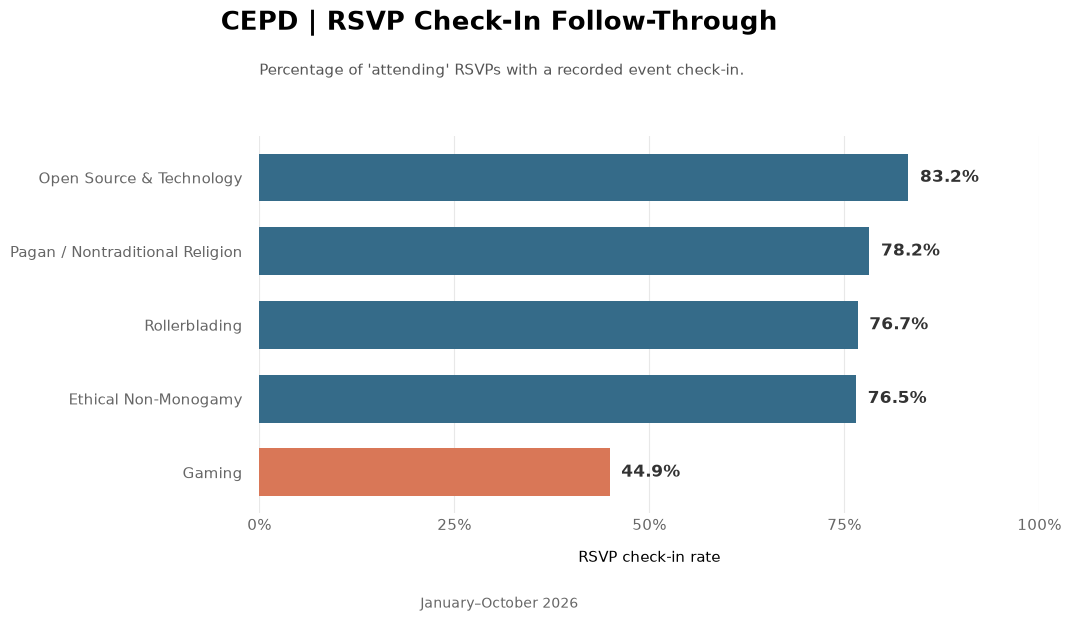

Saved visualization: output\rsvp_follow_through.png


In [7]:
chart_data = df.copy()

chart_data["check_in_rate_pct"] = pd.to_numeric(
    chart_data["check_in_rate_pct"]
)

chart_data = chart_data.sort_values(
    "check_in_rate_pct",
    ascending=False
)

# Shorten organization names for display.
short_names = {
    "Front Range Open Source & Technology Collective": "Open Source & Technology",
    "Pagan / Nontraditional Religion Community": "Pagan / Nontraditional Religion",
    "Rollerblading Community": "Rollerblading",
    "Ethical Non-Monogamy Community": "Ethical Non-Monogamy",
    "Gaming Community": "Gaming",
}

chart_data["label"] = chart_data["organization"].replace(short_names)

# Highlight Gaming.
colors = [
    "#D97757" if name == "Gaming Community" else "#356B89"
    for name in chart_data["organization"]
]

fig, ax = plt.subplots(figsize=(12, 6.5))

fig.patch.set_facecolor("white")

fig.subplots_adjust(
    left=0.30,
    right=0.95,
    top=0.77,
    bottom=0.19
)

bars = ax.barh(
    chart_data["label"],
    chart_data["check_in_rate_pct"],
    color=colors,
    height=0.65
)

ax.invert_yaxis()
ax.set_xlim(0, 100)


for bar, rate in zip(bars, chart_data["check_in_rate_pct"]):
    ax.text(
        rate + 1.5,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.1f}%",
        ha="left",
        va="center",
        color="#333333",
        fontsize=12,
        fontweight="bold"
    )

fig.suptitle(
    "CEPD | RSVP Check-In Follow-Through",
    fontsize=19,
    fontweight="bold",
    y=0.965
)

# Align the definition with the beginning of the bars.
left = ax.get_position().x0

fig.text(
    left,
    0.865,
    "Percentage of 'attending' RSVPs with a recorded event check-in.",
    ha="left",
    fontsize=11,
    color="#555555"
)

ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])

ax.set_xlabel(
    "RSVP check-in rate",
    fontsize=11,
    labelpad=12
)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=11,
    colors="#666666"
)

ax.tick_params(
    axis="y",
    pad=12
)

ax.grid(
    axis="x",
    color="#E8E8E8",
    linewidth=0.8
)

ax.set_axisbelow(True)

# Remove the rectangular border.
for spine in ax.spines.values():
    spine.set_visible(False)


# Annotations

fig.text(
    0.5,
    0.045,
    (
        "January–October 2026"
    ),
    ha="center",
    fontsize=10,
    color="#666666"
)

# Export and display

output_path = Path("output/rsvp_follow_through.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Saved visualization: {output_path}")
